In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [2]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Rows and columns: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# STEP 3.1: Check data quality

print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Dataset shape: (7043, 21)

Missing values in each column:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0
Duplicate customer IDs: 0


In [4]:
# STEP 3.2: Convert TotalCharges to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print(
    "Missing TotalCharges after conversion:",
    df["TotalCharges"].isnull().sum()
)

display(
    df[df["TotalCharges"].isnull()][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [5]:
# STEP 3.3: Investigate zero-tenure customers

mask = df["TotalCharges"].isnull() & (df["tenure"] == 0)

print("Missing charges with zero tenure:", mask.sum())

df.loc[mask, "TotalCharges"] = 0

print(
    "\nMissing TotalCharges remaining:",
    df["TotalCharges"].isnull().sum()
)

Missing charges with zero tenure: 11

Missing TotalCharges remaining: 0


In [6]:
# STEP 3.4: Remove exact duplicate rows

rows_before = len(df)

df = df.drop_duplicates().copy()

print("Rows before:", rows_before)
print("Rows after:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())
print(
    "Duplicate customer IDs remaining:",
    df["customerID"].duplicated().sum()
)

Rows before: 7043
Rows after: 7043
Duplicate rows remaining: 0
Duplicate customer IDs remaining: 0


In [7]:
# STEP 3.5: Detect potential outliers using IQR

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))


Column: tenure
Lower bound: -60.0
Upper bound: 124.0
Potential outliers: 0

Column: MonthlyCharges
Lower bound: -46.02
Upper bound: 171.38
Potential outliers: 0

Column: TotalCharges
Lower bound: -4683.52
Upper bound: 8868.67
Potential outliers: 0


In [8]:
# STEP 3.6: Final data-quality check

print("Final dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values remaining:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nChurn distribution:")
display(df["Churn"].value_counts(dropna=False))

print("\nCleaned dataset preview:")
display(df.head())

print("\nStatistical summary:")
display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()
)

Final dataset shape: (7043, 21)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing values remaining:


,0



Churn distribution:


,count
Churn,
No,5174
Yes,1869



Cleaned dataset preview:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Statistical summary:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


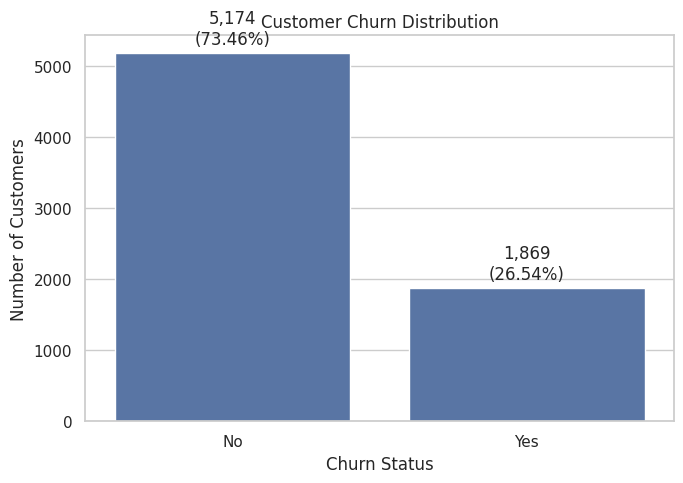

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Count customers in each churn category
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
percentages = churn_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    ax=ax
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{count:,}\n({percent:.2f}%)"
        for count, percent in zip(churn_counts, percentages)
    ],
    padding=4
)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()


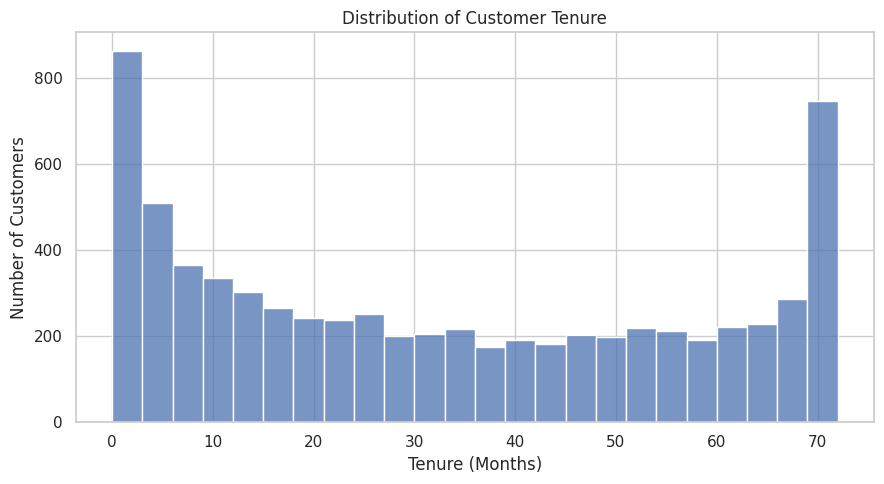

In [10]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=24
)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


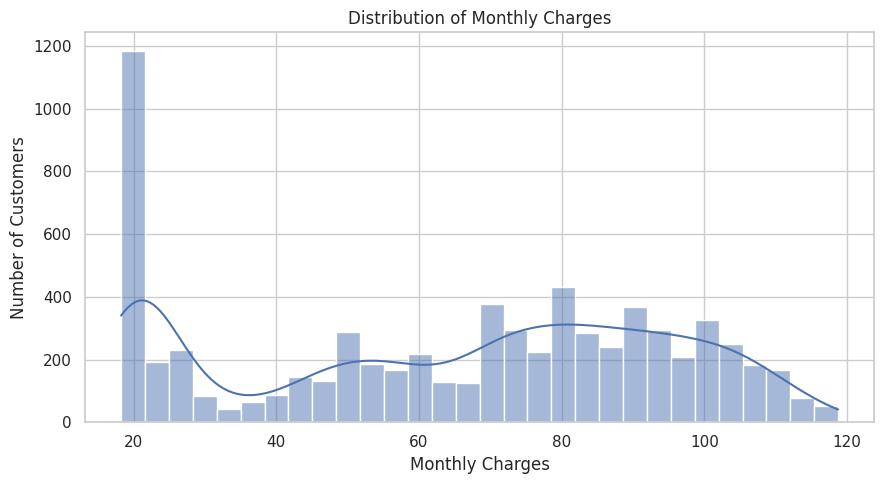

In [11]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=30,
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


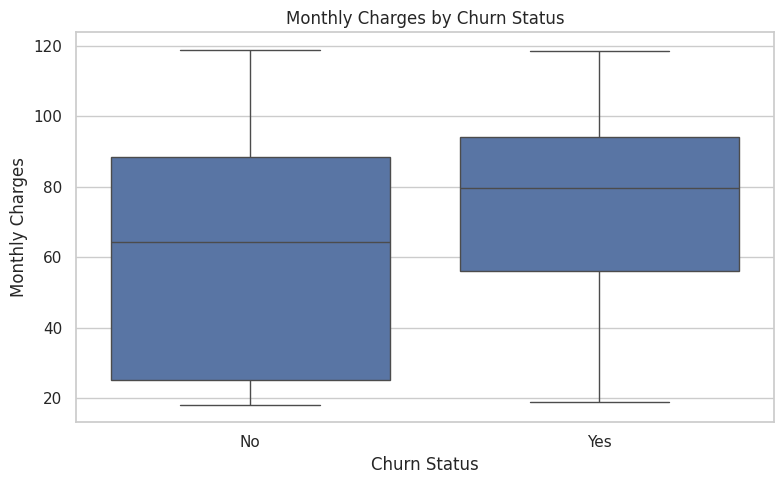

In [12]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


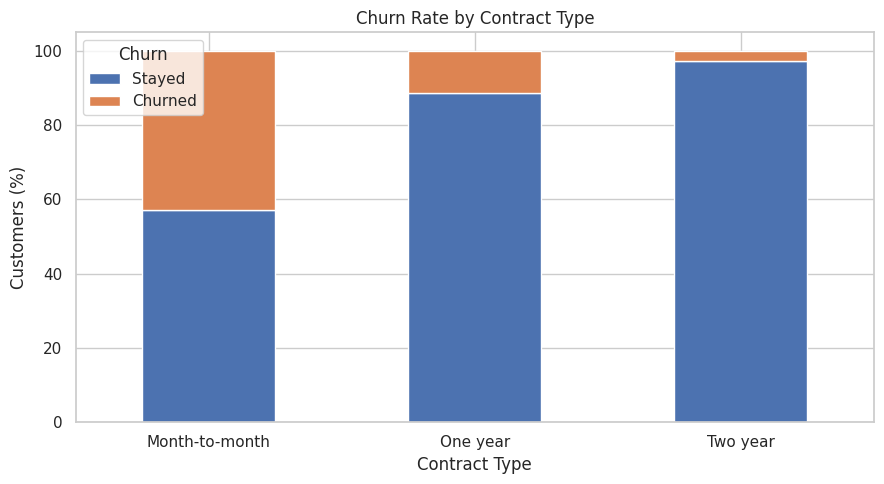

Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [13]:

contract_churn = (
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ) * 100
)

contract_churn = contract_churn.reindex(columns=["No", "Yes"])

ax = contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Customers (%)")
ax.legend(title="Churn", labels=["Stayed", "Churned"])
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Churn percentage by contract type:")
display(contract_churn.round(2))


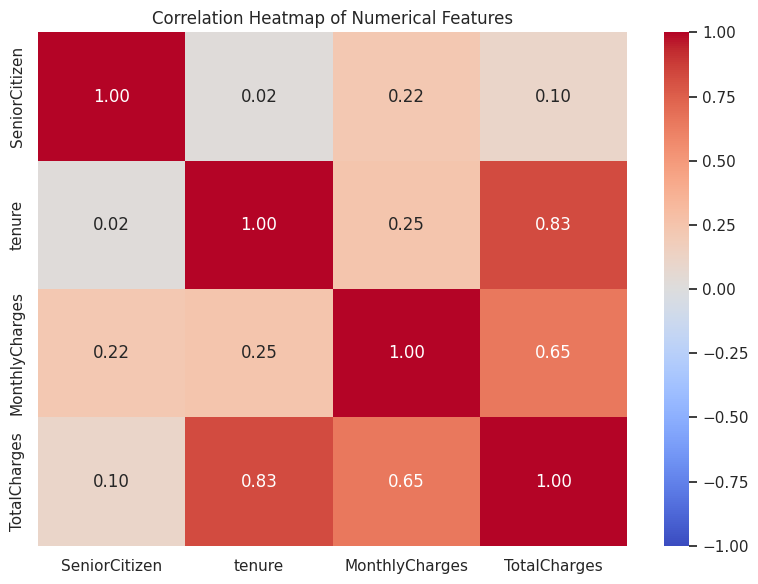

In [14]:

numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


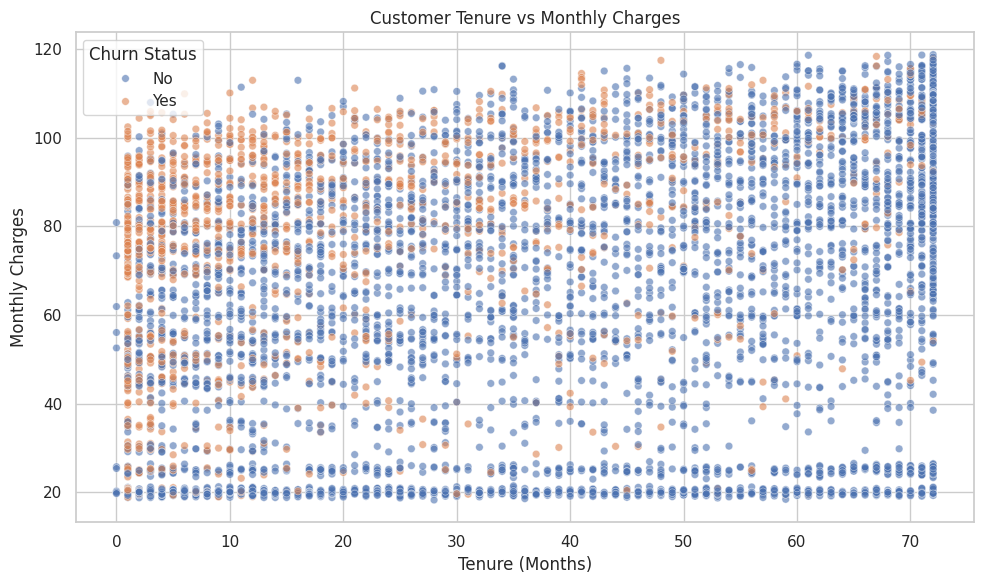

In [15]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.6,
    s=30
)

plt.title("Customer Tenure vs Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn Status")
plt.tight_layout()
plt.show()


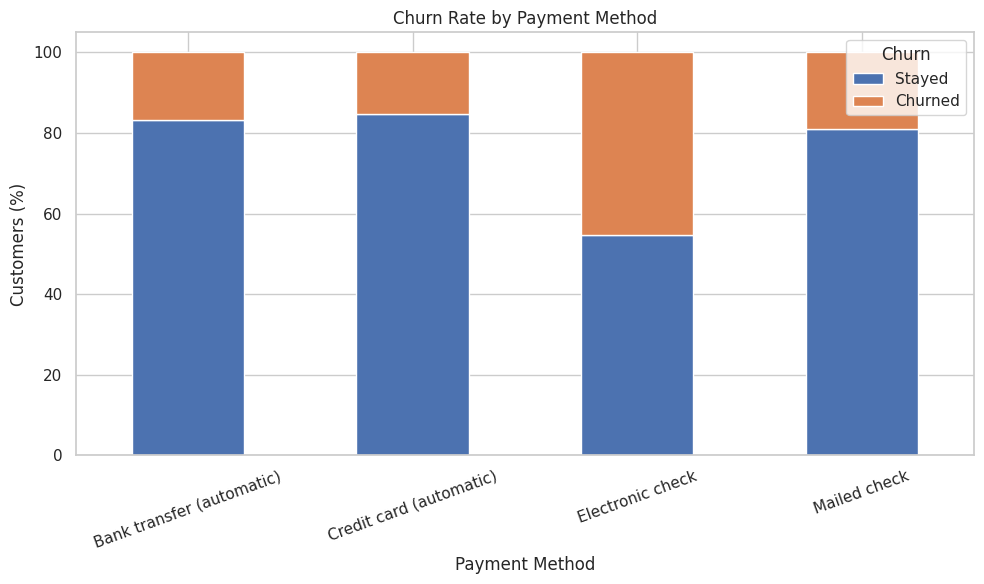

Churn percentage by payment method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [16]:

payment_churn = (
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"],
        normalize="index"
    ) * 100
)

payment_churn = payment_churn.reindex(columns=["No", "Yes"])

ax = payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title("Churn Rate by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Customers (%)")
ax.legend(title="Churn", labels=["Stayed", "Churned"])
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Churn percentage by payment method:")
display(payment_churn.round(2))


In [17]:

# Numerical summary statistics
display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)

# Churn percentages
print("Overall churn percentage:")
print((df["Churn"].eq("Yes").mean() * 100).round(2), "%")

# Mean monthly charges grouped by churn
print("\nMean monthly charges by churn status:")
display(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median", "std"])
    .round(2)
)

# Mean tenure grouped by churn
print("\nMean tenure by churn status:")
display(
    df.groupby("Churn")["tenure"]
    .agg(["mean", "median", "std"])
    .round(2)
)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


Overall churn percentage:
26.54 %

Mean monthly charges by churn status:


,mean,median,std
Churn,,,
No,61.27,64.43,31.09
Yes,74.44,79.65,24.67



Mean tenure by churn status:


,mean,median,std
Churn,,,
No,37.57,38.0,24.11
Yes,17.98,10.0,19.53


In [18]:

import plotly.express as px

# Use a reproducible sample for a responsive interactive chart
plot_df = df.sample(
    n=min(1500, len(df)),
    random_state=42
)

fig = px.scatter(
    plot_df,
    x="tenure",
    y="MonthlyCharges",
    color="Churn",
    hover_data=["Contract", "PaymentMethod"],
    title="Interactive Customer Churn Exploration"
)

fig.update_layout(
    xaxis_title="Tenure (Months)",
    yaxis_title="Monthly Charges"
)

fig.show()


In [19]:

# STATISTICAL ANALYSIS

# 1. Descriptive statistics
print("DESCRIPTIVE STATISTICS")
display(
    df[["tenure", "MonthlyCharges", "TotalCharges"]]
    .describe()
    .round(2)
)

# 2. Overall churn distribution
print("\nOVERALL CHURN DISTRIBUTION")
churn_summary = df["Churn"].value_counts()
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

display(pd.DataFrame({
    "Count": churn_summary,
    "Percentage": churn_percentage.round(2)
}))

# 3. Numerical statistics grouped by churn
print("\nNUMERICAL COMPARISON BY CHURN STATUS")
display(
    df.groupby("Churn")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

# 4. Contract-wise churn rate
print("\nCONTRACT-WISE CHURN RATE (%)")
display(
    df.groupby("Contract")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)


DESCRIPTIVE STATISTICS


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



OVERALL CHURN DISTRIBUTION


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54



NUMERICAL COMPARISON BY CHURN STATUS


tenure               MonthlyCharges               TotalCharges           \
        mean median    std           mean median    std         mean   median   
Churn                                                                           
No     37.57   38.0  24.11          61.27  64.43  31.09      2549.91  1679.52   
Yes    17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55   

                
           std  
Churn           
No     2329.95  
Yes    1890.82


CONTRACT-WISE CHURN RATE (%)


,Churn
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [20]:

# STEP 5.1: Split the dataset into train, validation and test sets

from sklearn.model_selection import train_test_split

# Exclude customerID because it is an identifier, not a useful predictor
X = df.drop(columns=["customerID", "Churn"]).copy()

# Convert the target into binary values
# No = 0, Yes = 1
y = df["Churn"].map({"No": 0, "Yes": 1})

# Check that the target conversion worked
assert y.notna().all(), "Unexpected values found in Churn!"

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
# Final proportions: 70% train, 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))
print("Total records:", len(X_train) + len(X_val) + len(X_test))

print("\nChurn percentage in each partition:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")


Training records: 4930
Validation records: 1056
Testing records: 1057
Total records: 7043

Churn percentage in each partition:
Train: 26.53 %
Validation: 26.52 %
Test: 26.58 %


In [5]:

# STEP 5: Reload data, clean, split and preprocess
# Run this entire cell from beginning to end.

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Reload the dataset
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset loaded:", df.shape)

# 2. Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Zero-tenure customers with blank charges
mask = df["TotalCharges"].isna() & (df["tenure"] == 0)
df.loc[mask, "TotalCharges"] = 0

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df.shape)
print("Missing values remaining:", int(df.isna().sum().sum()))

# 3. Separate features and target
X = df.drop(columns=["customerID", "Churn"]).copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

assert y.notna().all(), "Unexpected values found in Churn"

# 4. Split: 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\n--- Dataset Split ---")
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

# 5. Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# 6. Prepare a compatible OneHotEncoder
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# 7. Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit transformations ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# 8. Convert data into arrays for TensorFlow
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)
X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)
X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

# 9. Final verification
print("\n--- Preprocessing Completed ---")
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print(
    "NaN values in training features:",
    int(np.isnan(X_train_processed).sum())
)

print(
    "NaN values in validation features:",
    int(np.isnan(X_val_processed).sum())
)

print(
    "NaN values in testing features:",
    int(np.isnan(X_test_processed).sum())
)

print("\nSUCCESS: Data is ready for Deep Learning!")


Dataset loaded: (7043, 21)
Cleaned dataset shape: (7043, 21)
Missing values remaining: 0

--- Dataset Split ---
Training records: 4930
Validation records: 1056
Testing records: 1057

--- Preprocessing Completed ---
Training shape: (4930, 45)
Validation shape: (1056, 45)
Testing shape: (1057, 45)
NaN values in training features: 0
NaN values in validation features: 0
NaN values in testing features: 0

SUCCESS: Data is ready for Deep Learning!


In [6]:

# STEP 6.1: Build, train and compare two MLP models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Build a configurable MLP
def build_mlp(hidden_units, dropout_rate, learning_rate):
    model = keras.Sequential()

    model.add(
        layers.Input(shape=(X_train_processed.shape[1],))
    )

    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model


# Two hyperparameter configurations
configurations = [
    {
        "name": "Model A",
        "hidden_units": [64, 32],
        "dropout": 0.2,
        "learning_rate": 0.001
    },
    {
        "name": "Model B",
        "hidden_units": [32, 16],
        "dropout": 0.3,
        "learning_rate": 0.0005
    }
]

models = {}
histories = {}
results = []

for config in configurations:
    print("\nTraining", config["name"])

    model = build_mlp(
        hidden_units=config["hidden_units"],
        dropout_rate=config["dropout"],
        learning_rate=config["learning_rate"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_processed,
        y_train,
        validation_data=(X_val_processed, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=1
    )

    models[config["name"]] = model
    histories[config["name"]] = history

    # Compare using validation AUC
    best_epoch = int(np.argmin(history.history["val_loss"]))
    best_val_loss = float(history.history["val_loss"][best_epoch])
    best_val_auc = float(history.history["val_auc"][best_epoch])

    results.append({
        "Model": config["name"],
        "Hidden layers": str(config["hidden_units"]),
        "Dropout": config["dropout"],
        "Learning rate": config["learning_rate"],
        "Best epoch": best_epoch + 1,
        "Best validation loss": best_val_loss,
        "Validation AUC at best-loss epoch": best_val_auc
    })

# Display model comparison
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Validation AUC at best-loss epoch",
        ascending=False
    ).round(4)
)

# Select a model using validation AUC at its best-loss epoch
best_model_name = results_df.loc[
    results_df["Validation AUC at best-loss epoch"].idxmax(),
    "Model"
]

best_model = models[best_model_name]
best_history = histories[best_model_name]

print("\nSelected model:", best_model_name)
print("Selection is based on validation data, not test performance.")



Training Model A
Epoch 1/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7544 - auc: 0.7704 - loss: 0.4897 - precision: 0.5488 - recall: 0.4167 - val_accuracy: 0.8030 - val_auc: 0.8389 - val_loss: 0.4275 - val_precision: 0.6475 - val_recall: 0.5643
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7911 - auc: 0.8265 - loss: 0.4376 - precision: 0.6324 - recall: 0.5076 - val_accuracy: 0.8040 - val_auc: 0.8438 - val_loss: 0.4207 - val_precision: 0.6454 - val_recall: 0.5786
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - auc: 0.8374 - loss: 0.4255 - precision: 0.6499 - recall: 0.5336 - val_accuracy: 0.8021 - val_auc: 0.8422 - val_loss: 0.4213 - val_precision: 0.6461 - val_recall: 0.5607
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7986 - auc: 0.8371 - loss: 0.4265 - precision: 0.6537 - recall: 0.5122 - val_accuracy: 0.8011 - val_auc: 0.8413 - val_loss: 0.4224 - val_precision: 0.6522 - val_recall: 0.5357
Epoch 5/50
155

,Model,Hidden layers,Dropout,Learning rate,Best epoch,Best validation loss,Validation AUC at best-loss epoch
1,Model B,"[32, 16]",0.3,0.0005,31,0.4197,0.8450
0,Model A,"[64, 32]",0.2,0.0010,2,0.4207,0.8438



Selected model: Model B
Selection is based on validation data, not test performance.


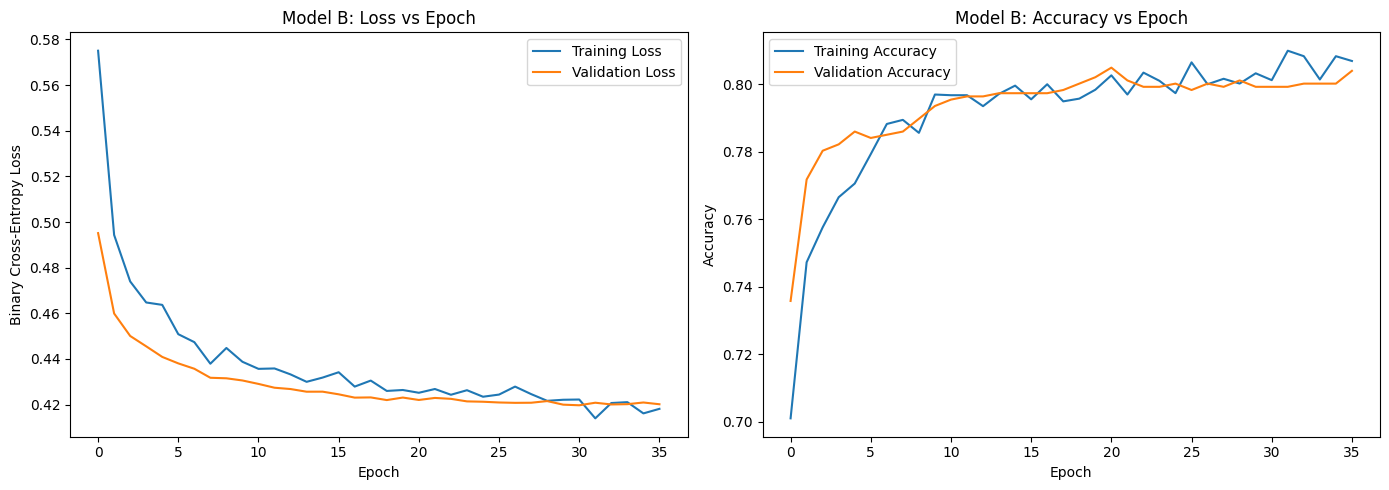

In [7]:

# STEP 6.2: Visualize training and validation performance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss vs Epoch
axes[0].plot(
    best_history.history["loss"],
    label="Training Loss"
)
axes[0].plot(
    best_history.history["val_loss"],
    label="Validation Loss"
)
axes[0].set_title(f"{best_model_name}: Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()

# Accuracy vs Epoch
axes[1].plot(
    best_history.history["accuracy"],
    label="Training Accuracy"
)
axes[1].plot(
    best_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].set_title(f"{best_model_name}: Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


In [8]:

# STEP 6.3: Save the selected model

best_model.save("telco_churn_mlp.keras")

print("Saved model: telco_churn_mlp.keras")


Saved model: telco_churn_mlp.keras


In [9]:

# STEP 7.1: Final evaluation on unseen test data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

# Generate churn probabilities using the selected model
y_test_prob = best_model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Apply the default threshold of 0.5
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, zero_division=0
)
test_recall = recall_score(
    y_test, y_test_pred, zero_division=0
)
test_f1 = f1_score(
    y_test, y_test_pred, zero_division=0
)
test_auc = roc_auc_score(y_test, y_test_prob)

# Display the metrics
test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

print("Selected model:", best_model_name)
print("\nFINAL TEST RESULTS")
display(test_results.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Stayed (No)", "Churned (Yes)"],
    zero_division=0
))


Selected model: Model B

FINAL TEST RESULTS


,Metric,Score
0,Accuracy,0.7994
1,Precision,0.6635
2,Recall,0.4982
3,F1-score,0.5691
4,ROC-AUC,0.8412



CLASSIFICATION REPORT
               precision    recall  f1-score   support

  Stayed (No)       0.83      0.91      0.87       776
Churned (Yes)       0.66      0.50      0.57       281

     accuracy                           0.80      1057
    macro avg       0.75      0.70      0.72      1057
 weighted avg       0.79      0.80      0.79      1057



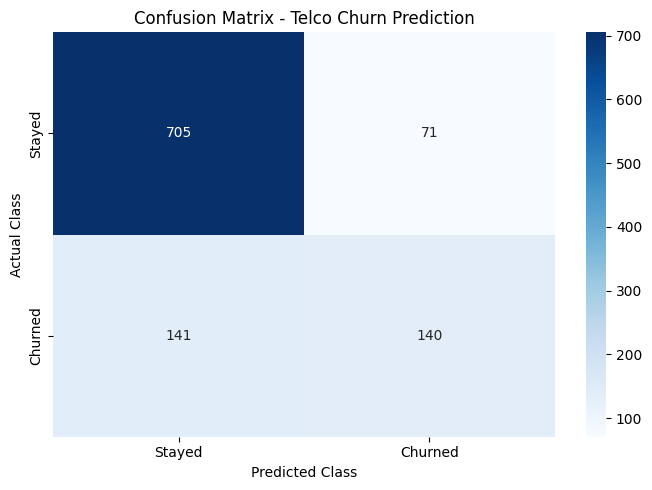

Confusion matrix order:
Rows = Actual; Columns = Predicted
[[705  71]
 [141 140]]


In [10]:

# STEP 7.2: Confusion matrix

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Telco Churn Prediction")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix order:")
print("Rows = Actual; Columns = Predicted")
print(cm)


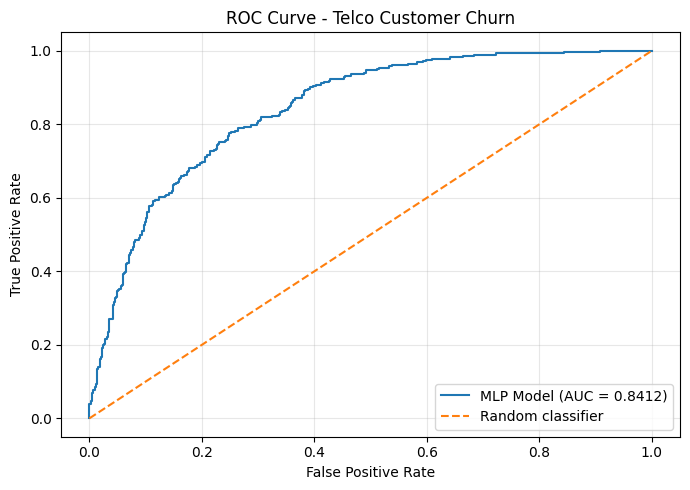

Test ROC-AUC: 0.8412


In [11]:

# STEP 7.3: ROC curve and AUC

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"MLP Model (AUC = {test_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve - Telco Customer Churn")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print(f"Test ROC-AUC: {test_auc:.4f}")


In [12]:

# STEP 7.4: Export final test metrics

test_results.to_csv(
    "test_evaluation_metrics.csv",
    index=False
)

print("Saved: test_evaluation_metrics.csv")
print("Saved: confusion_matrix.png")
print("Saved: roc_curve.png")


Saved: test_evaluation_metrics.csv
Saved: confusion_matrix.png
Saved: roc_curve.png


Baseline validation ROC-AUC: 0.8448

Feature importance ranking:


,Feature,Importance
4,tenure,0.0528
14,Contract,0.0460
7,InternetService,0.0147
18,TotalCharges,0.0080
11,TechSupport,0.0053
17,MonthlyCharges,0.0051
13,StreamingMovies,0.0037
6,MultipleLines,0.0036
15,PaperlessBilling,0.0028
1,SeniorCitizen,0.0019


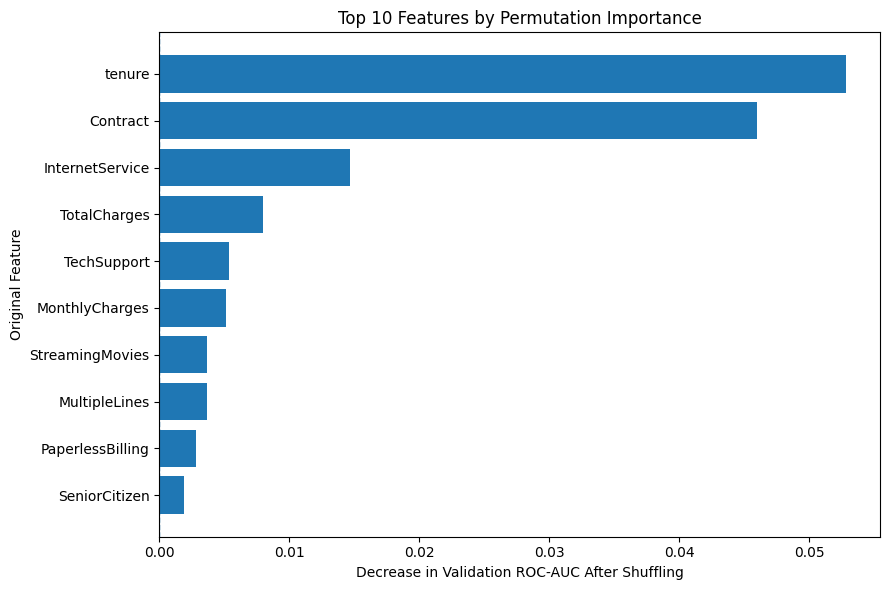

In [13]:

# STEP 8.1: Permutation feature importance
# Uses validation data, not the held-out test set.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)

# Baseline validation ROC-AUC
baseline_prob = best_model.predict(
    X_val_processed, verbose=0
).ravel()

baseline_auc = roc_auc_score(y_val, baseline_prob)

importance_results = []

# Shuffle each original feature and measure the change in AUC
for feature in X_val.columns:
    auc_scores = []

    for repeat in range(3):
        permuted_X = X_val.copy()

        permuted_X[feature] = rng.permutation(
            permuted_X[feature].to_numpy()
        )

        permuted_processed = preprocessor.transform(
            permuted_X
        )

        permuted_processed = np.asarray(
            permuted_processed,
            dtype=np.float32
        )

        probabilities = best_model.predict(
            permuted_processed,
            verbose=0
        ).ravel()

        auc_scores.append(
            roc_auc_score(y_val, probabilities)
        )

    importance_results.append({
        "Feature": feature,
        "Importance": baseline_auc - np.mean(auc_scores)
    })

importance_df = (
    pd.DataFrame(importance_results)
    .sort_values("Importance", ascending=False)
)

print("Baseline validation ROC-AUC:", round(baseline_auc, 4))
print("\nFeature importance ranking:")
display(importance_df.round(4))

# Visualize the ten most important features
top_features = importance_df.head(10).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.axvline(0, linestyle="--", linewidth=1)
plt.title("Top 10 Features by Permutation Importance")
plt.xlabel("Decrease in Validation ROC-AUC After Shuffling")
plt.ylabel("Original Feature")
plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

# STEP 10.1: Save the main project outputs

import os
import shutil
import pandas as pd

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("report", exist_ok=True)

# Save the selected Deep Learning model
best_model.save("telco_churn_mlp.keras")

# Save test metrics
test_results.to_csv(
    "outputs/test_evaluation_metrics.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

print("Main outputs saved successfully.")


Main outputs saved successfully.
